<a href="https://colab.research.google.com/github/Shreyask28/House_Prices_Analysis/blob/main/EDA_House_Prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***EXPLORATORY ANALYSIS OF HOUSE PRICES***

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt,seaborn as sns,scipy.stats as stats

importing training dataset

In [3]:
df = pd.read_csv('/content/train.csv')

In [4]:
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


the dataset have 1460 X 81 shape, and PoolQc has highest missing percentage of values

In [15]:
print(df.shape)
print(df.head())
df.info()
missing = df.isnull().sum()
missing = missing.sort_values(ascending=False)
missing_percentage = (missing / len(df)) * 100
print("\n")
missing_summary = pd.DataFrame({
    'Missing Values': missing,
    'Missing Percentage': missing_percentage
})

missing_summary = missing_summary[missing_summary['Missing Values'] > 0]

print(missing_summary)

(1460, 81)
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   2008  

In [34]:
numeric_cols = df.select_dtypes(int).columns
print(numeric_cols)
print("\n")
categorical_cols = df.select_dtypes(object).columns
print(categorical_cols)
ordinal_map = {
    'ExterQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'KitchenQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],

}
for column in ordinal_map:
    df[column] = pd.Categorical(
        df[column],
        categories=ordinal_map[column],
        ordered=True
    )

    # 1. Identify numerical columns
numeric_cols = df.select_dtypes(include='number').columns

# 2. Identify categorical columns
categorical_cols = df.select_dtypes(include='object').columns

# 3. Define ordinal mapping
ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

# 4. Convert ordinal columns
for column in ordinal_map:
    df[column] = pd.Categorical(
        df[column],
        categories=ordinal_map[column],
        ordered=True
    )

# 5. Build summary table
summary = []

for column in df.columns:

    if column in ordinal_map:
        col_type = "Ordinal"
    elif column in numeric_cols:
        col_type = "Numerical"
    elif column in categorical_cols:
        col_type = "Categorical"
    else:
        col_type = "Other"

    summary.append({
        "Column Name": column,
        "Type": col_type,
        "Unique Values": df[column].nunique(),
        "Example Values": df[column].dropna().unique()[:5].tolist()
    })

# 6. Display summary
summary_df = pd.DataFrame(summary)
display(summary_df)




Index(['Id', 'MSSubClass', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
       'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea',
       'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr',
       'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars',
       'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch',
       'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='object')


Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', 'Functional', 'Firepla

,Column Name,Type,Unique Values,Example Values
0,Id,Numerical,1460,"[1, 2, 3, 4, 5]"
1,MSSubClass,Numerical,15,"[60, 20, 70, 50, 190]"
2,MSZoning,Categorical,5,"[RL, RM, C (all), FV, RH]"
3,LotFrontage,Numerical,110,"[65.0, 80.0, 68.0, 60.0, 84.0]"
4,LotArea,Numerical,1073,"[8450, 9600, 11250, 9550, 14260]"
...,...,...,...,...
76,MoSold,Numerical,12,"[2, 5, 9, 12, 10]"
77,YrSold,Numerical,5,"[2008, 2007, 2006, 2009, 2010]"
78,SaleType,Categorical,9,"[WD, New, COD, ConLD, ConLI]"
79,SaleCondition,Categorical,6,"[Normal, Abnorml, Partial, AdjLand, Alloca]"


From above output 👆 OverallQual is stored as a number but is really ordinal. Mention this in your notes.

Descriptive Statistics

In [37]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [38]:
for column in ['SalePrice', 'GrLivArea', 'LotArea']:

    mean = df[column].mean()
    median = df[column].median()
    mode = df[column].mode()[0]

    print(f"\nStatistics for {column}")
    print("Mean:", mean)
    print("Median:", median)
    print("Mode:", mode)


Statistics for SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000

Statistics for GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: 864

Statistics for LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200


The Mean > Median

## Distrubution

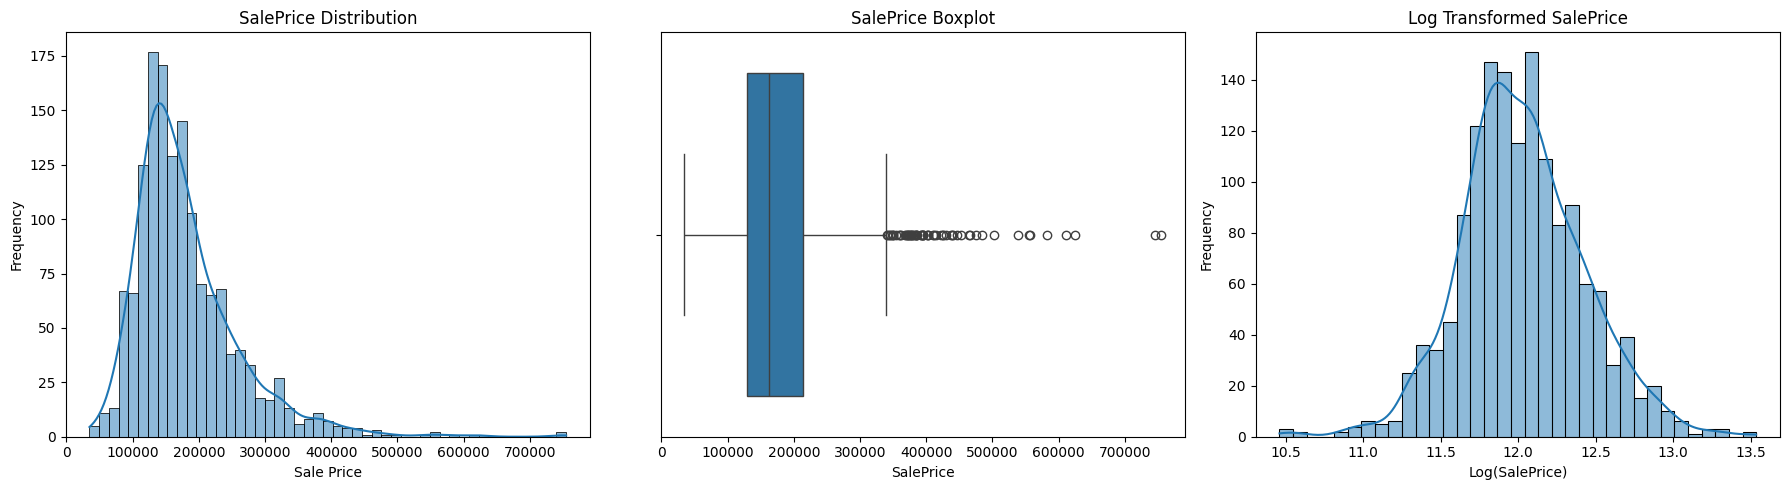

In [39]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogram with KDE
sns.histplot(df['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('SalePrice Distribution')
axes[0].set_xlabel('Sale Price')
axes[0].set_ylabel('Frequency')

# 2. Boxplot
sns.boxplot(x=df['SalePrice'], ax=axes[1])
axes[1].set_title('SalePrice Boxplot')

# 3. Histogram after log transformation
sns.histplot(np.log1p(df['SalePrice']), kde=True, ax=axes[2])
axes[2].set_title('Log Transformed SalePrice')
axes[2].set_xlabel('Log(SalePrice)')
axes[2].set_ylabel('Frequency')

plt.tight_layout()
plt.show()
